# 16.13 - Midline seam review batch

A simple grayscale seam score ranks source-train images for visual inspection. It is a retrieval aid, not a disease classifier. Eight original images with visible separation of the upper central incisors were manually inspected and boxed by Codex. Other target status remains uncertain.

In [1]:
from pathlib import Path
import hashlib, sys
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Code
root=Path.cwd().resolve()
while not (root / "AGENTS.md").exists():
    if root==root.parent: raise RuntimeError("Project root not found")
    root=root.parent
base=root / "data/processed/alignment_omni_frontal_candidates"
queue=pd.read_csv(base / "review_queue.csv",dtype={"source_image_id":str,"sha256":str}).set_index("source_image_id")
rank=pd.read_csv(root / "docs/reports/alignment/midline_heuristic_review/ranking.csv",dtype={"source_image_id":str}).set_index("source_image_id")
excluded=set(pd.read_csv(root / "docs/reports/alignment/omni_frontal_candidate_audit/conservative_train_exclusions.csv",dtype=str).source_image_id)

## 1. Read retrieval evidence

The score searches for a darker central stripe between brighter left and right regions in a limited upper-anterior band. It is sensitive to occlusion, restoration, lighting and mouth framing. Rank is used only for selecting images to inspect.

,score
count,538.000000
mean,778.645279
std,420.751205
min,0.000000
25%,555.065000
50%,703.335000
75%,990.892500
max,1968.000000


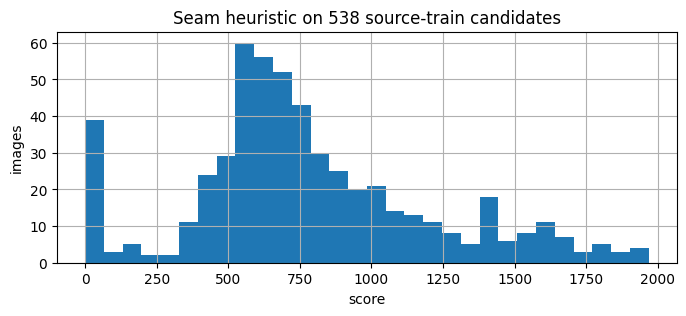

Implementation:


"""Rank OMNI source-train images by central dark-seam evidence for visual review."""
from __future__ import annotations

import csv
from pathlib import Path

import numpy as np
from PIL import Image, ImageDraw

ROOT = Path(__file__).resolve().parents[2]
SOURCE = ROOT / 'data/processed/alignment_omni_frontal_candidates/review_queue.csv'
OUT = ROOT / 'docs/reports/alignment/midline_heuristic_review'


def seam_score(path: Path):
    with Image.open(path) as image:
        array = np.asarray(image.convert('L'), dtype=np.float32)
    h, w = array.shape
    if (w, h) != (512, 341):
        array = np.asarray(Image.fromarray(array.astype('uint8')).resize((512, 341)), dtype=np.float32)
    best = 0.0
    best_x = None
    for x in range(218, 296):
        left = array[115:220, x - 17:x - 8].mean(axis=1)
        mid = array[115:220, x - 2:x + 3].mean(axis=1)
        right = array[115:220, x + 8:x + 17].mean(axis=1)
        evidence = np.minimum(left, right) - mid
        valid = (left > 120) & (right > 120) & (evidence > 15)
        for start in range(0, len(evidence) - 12):
            band = evidence[start:start+13]
            support = valid[start:start+13]
            score = float((band * support).sum())
            if score > best:
                best, best_x = score, x
    return round(best, 2), best_x


def main():
    with SOURCE.open(encoding='utf-8-sig', newline='') as file:
        rows = [r for r in csv.DictReader(file) if r['split'] == 'train']
    OUT.mkdir(parents=True, exist_ok=True)
    ranking = []
    for row in rows:
        score, x = seam_score(ROOT / row['image_path'])
        ranking.append({'source_image_id': row['source_image_id'], 'image_path': row['image_path'],
                        'seam_score': score, 'seam_x': x})
    ranking.sort(key=lambda r: -r['seam_score'])
    with (OUT / 'ranking.csv').open('w', encoding='utf-8', newline='') as file:
        writer = csv.DictWriter(file, fieldnames=ranking[0].keys())
        writer.writeheader()
        writer.writerows(ranking)
    for page in range(0, 72, 12):
        sheet = Image.new('RGB', (512 * 4, 375 * 3), 'white')
        draw = ImageDraw.Draw(sheet)
        for idx, row in enumerate(ranking[page:page + 12]):
            with Image.open(ROOT / row['image_path']) as image:
                thumb = image.convert('RGB')
                thumb.thumbnail((510, 340))
            x, y = idx % 4 * 512, idx // 4 * 375
            sheet.paste(thumb, (x, y + 25))
            draw.text((x + 5, y + 5), f'{row["source_image_id"]} {row["seam_score"]:.0f}', fill='black')
        sheet.save(OUT / f'top_{page//12+1}.jpg', quality=90)
    lookup = {r['source_image_id']: r['seam_score'] for r in ranking}
    for id in ('201916202112081', '202139202205251', '202212202202071',
               '202362202308141', '201875201810241', '202243202207131', '201883201809131'):
        print(id, lookup[id], next(i+1 for i, r in enumerate(ranking) if r['source_image_id'] == id))


if __name__ == '__main__':
    main()

In [2]:
display(rank.seam_score.describe().to_frame("score"))
rank.seam_score.hist(bins=30,figsize=(8,3)); plt.title("Seam heuristic on 538 source-train candidates"); plt.xlabel("score"); plt.ylabel("images"); plt.show()
print("Implementation:")
display(Code((root / "src/scripts/rank_midline_gap_heuristic.py").read_text(encoding="utf-8"),language="python"))

## 2. Enter verified image-level observations and boxes

Boxes contain both upper central incisors. The entire source-train image is hash-checked. A visible gap here is a visual research target, not a measured clinical diagnosis. The crowding status remains uncertain.

In [3]:
boxes=pd.DataFrame([
    ("202211202201261",150,106,335,183),
    ("202242202207211",143,105,337,202),
    ("202279202212011",176,118,325,193),
    ("2021111202204151",171,78,340,177),
    ("202347202305071",165,142,320,211),
    ("202164202107211",164,105,327,185),
    ("202279202306291",164,126,329,202),
    ("202195202108311",156,115,346,194),
],columns=["source_image_id","x_min","y_min","x_max","y_max"])
boxes["target"]="upper_midline_diastema"
boxes["reviewer"]="Codex visual review"
boxes["review_state"]="agent_visual_provisional"
for r in boxes.itertuples():
    s=queue.loc[r.source_image_id]
    assert s["split"]=="train" and r.source_image_id not in excluded
    assert hashlib.sha256((root / s["image_path"]).read_bytes()).hexdigest()==s["sha256"]
    assert 0<=r.x_min<r.x_max<=int(s["width"]) and 0<=r.y_min<r.y_max<=int(s["height"])
states=pd.DataFrame({"source_image_id":boxes.source_image_id,"view_review":"frontal",
    "diastema_review":"present","crowding_review":"uncertain",
    "reviewer":"Codex visual review","review_state":"agent_visual_provisional",
    "visual_reason":"visible upper central separation"})
display(states.assign(seam_score=[rank.loc[id,"seam_score"] for id in states.source_image_id]))

,source_image_id,view_review,diastema_review,crowding_review,reviewer,review_state,visual_reason,seam_score
0,202211202201261,frontal,present,uncertain,Codex visual review,agent_visual_provisional,visible upper central separation,1968.00
1,202242202207211,frontal,present,uncertain,Codex visual review,agent_visual_provisional,visible upper central separation,1957.87
2,202279202212011,frontal,present,uncertain,Codex visual review,agent_visual_provisional,visible upper central separation,1846.56
3,2021111202204151,frontal,present,uncertain,Codex visual review,agent_visual_provisional,visible upper central separation,1805.09
4,202347202305071,frontal,present,uncertain,Codex visual review,agent_visual_provisional,visible upper central separation,1790.16
5,202164202107211,frontal,present,uncertain,Codex visual review,agent_visual_provisional,visible upper central separation,1757.27
6,202279202306291,frontal,present,uncertain,Codex visual review,agent_visual_provisional,visible upper central separation,1728.07
7,202195202108311,frontal,present,uncertain,Codex visual review,agent_visual_provisional,visible upper central separation,1702.78


## 3. Visually inspect all proposed boxes

The figure is saved as a review artifact. Any box extending beyond the two central crowns should be corrected before use in an exploratory detector.

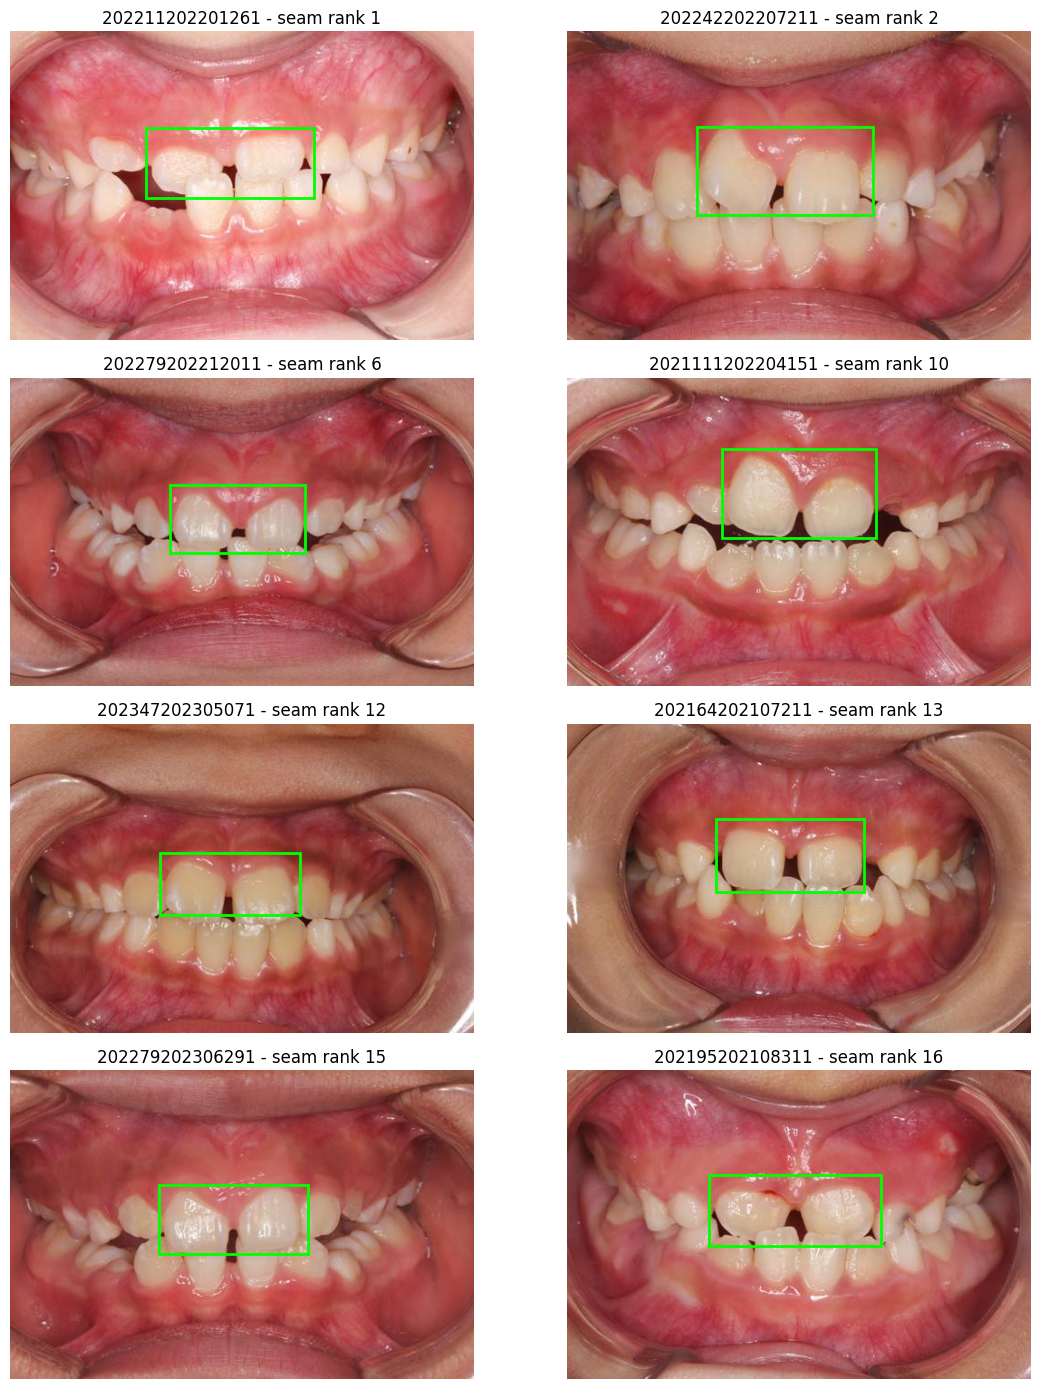

In [4]:
fig,axes=plt.subplots(4,2,figsize=(12,14))
for ax,r in zip(axes.flat,boxes.itertuples()):
    ax.imshow(Image.open(root / queue.loc[r.source_image_id,"image_path"]))
    ax.add_patch(plt.Rectangle((r.x_min,r.y_min),r.x_max-r.x_min,r.y_max-r.y_min,fill=False,color="lime",lw=2))
    ax.set_title(f"{r.source_image_id} - seam rank {rank.index.get_loc(r.source_image_id)+1}")
    ax.axis("off")
fig.tight_layout()
out=root / "docs/reports/alignment/agent_visual_pilot"
fig.savefig(out / "heuristic_review_boxes.png",dpi=150)
plt.show(); plt.close(fig)

## 4. Save provisional review evidence

Source validation and original test were not used to select this batch. These examples add support for annotation development; they are not an unbiased model evaluation.

In [5]:
for name,frame in (("heuristic_review_states.csv",states),("heuristic_review_boxes.csv",boxes)):
    path=out / name
    if path.exists(): assert pd.read_csv(path,dtype={"source_image_id":str}).equals(frame),f"Existing file differs: {path}"
    else: frame.to_csv(path,index=False)
    print("Saved",path)
print("New visual gap positives:",len(boxes))

Saved C:\Users\huynh\Desktop\oral-disease\docs\reports\alignment\agent_visual_pilot\heuristic_review_states.csv
Saved C:\Users\huynh\Desktop\oral-disease\docs\reports\alignment\agent_visual_pilot\heuristic_review_boxes.csv
New visual gap positives: 8
